# SKACE-Time-Data: Academic Validation Report
This interactive notebook explores the 40 paradata behavioral features extracted from the 4-Layer Validation Architecture. It mathematically validates the `AnomalyDetector` engine against both structural bounds and temporal entropy distributions.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')

file_path = '../output/features_output_20260325_095531.csv'
df = pd.read_csv(file_path)
print(f"Loaded {len(df)} discrete interview records.")
df.head()

Loaded 24 discrete interview records.


,file_name,interview_id,V-01_total_interview_duration_ms,V-02_speed_trajectory_early,V-03_speed_trajectory_late,V-04_speed_trajectory_ratio,V-06_back_navigation_total_count,V-05_back_navigation_rate,V-07_time_of_day_hour,V-08_day_of_week,...,flag_uniform_timing,flag_rule_pause,flag_population_pattern,flag_iqr_duration,flag_high_back_nav,is_data_quality_issue,anomaly_score,anomaly_category,is_anomalous_behavior,is_anomalous
0,ground_truth_labels.csv,INT400,NaN,NaN,NaN,NaN,0,0.0,NaN,NaN,...,1,0,0,0,0,1,13,minor_dq,0,1
1,ground_truth_labels.csv,INT401,NaN,NaN,NaN,NaN,0,0.0,NaN,NaN,...,1,0,0,0,0,1,13,minor_dq,0,1
2,ground_truth_labels.csv,INT402,NaN,NaN,NaN,NaN,0,0.0,NaN,NaN,...,1,0,0,0,0,1,13,minor_dq,0,1
3,ground_truth_labels.csv,INT403,NaN,NaN,NaN,NaN,0,0.0,NaN,NaN,...,1,0,0,0,0,1,13,minor_dq,0,1
4,ground_truth_labels.csv,INT404,NaN,NaN,NaN,NaN,0,0.0,NaN,NaN,...,1,0,0,0,0,1,13,minor_dq,0,1


## 1. Categorical Distribution of Anomaly Flags
The pipeline categorizes records into exactly 4 isolated bins to isolate physical device corruption (`dq_issue`) from organic human behavior (`normal`) and varying degrees of behavioral fraud (`suspicious`, `anomalous`).

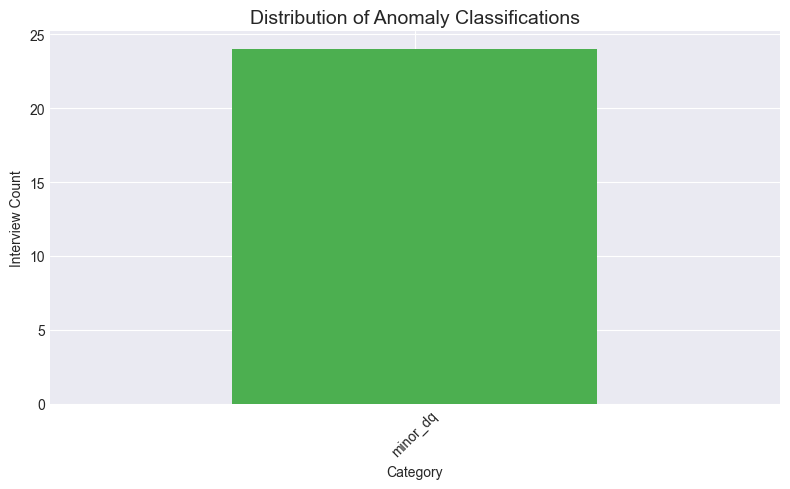

In [2]:
plt.figure(figsize=(8, 5))
counts = df['anomaly_category'].value_counts()
counts.plot(kind='bar', color=['#4CAF50', '#FFC107', '#F44336', '#9E9E9E'])
plt.title('Distribution of Anomaly Classifications', fontsize=14)
plt.xlabel('Category')
plt.ylabel('Interview Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2. Statistical Rhythm vs Structural Duration (Shannon Entropy)
A critical requirement for detecting 'Smart Fabricators' involves evaluating variance (`T-01`) and temporal rhythm (`T-03_rt_entropy`). Fabricators natively generate low entropy due to mechanical interaction repetition.

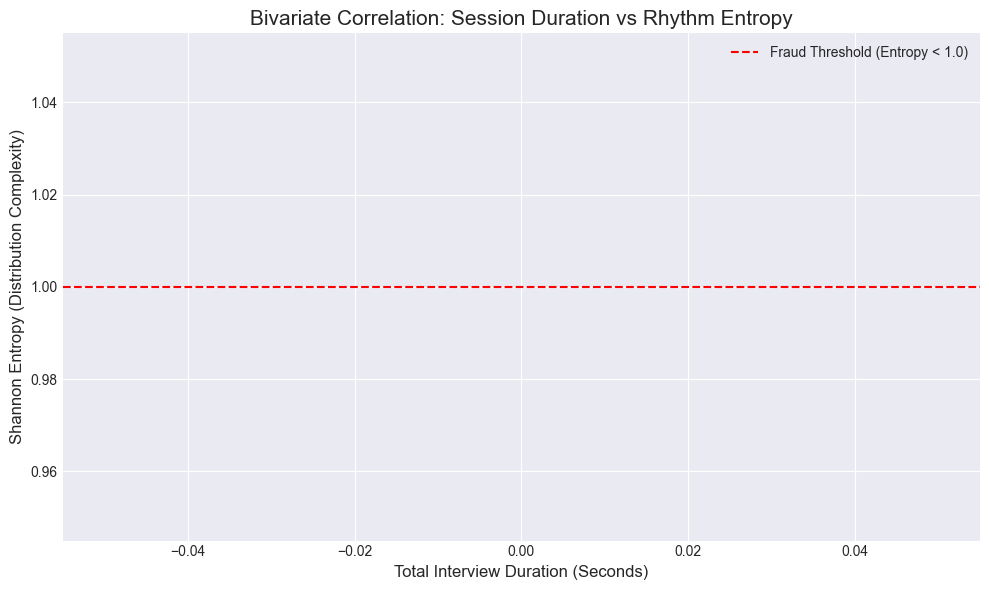

In [3]:
if 'V-01_total_interview_duration_ms' in df.columns and 'T-03_rt_entropy' in df.columns:
    plt.figure(figsize=(10, 6))
    # Shield outliers purely for graphical zoom
    q95 = df['V-01_total_interview_duration_ms'].quantile(0.95)
    plot_df = df[df['V-01_total_interview_duration_ms'] <= q95]

    # Map colors
    color_map = {'normal': 'blue', 'suspicious': 'orange', 'anomalous': 'red', 'strong_anomaly': 'red', 'minor_dq': 'black', 'dq_issue': 'black'}
    plot_df['color'] = plot_df['anomaly_category'].map(color_map).fillna('grey')

    plt.scatter(plot_df['V-01_total_interview_duration_ms'] / 1000, 
                plot_df['T-03_rt_entropy'], 
                c=plot_df['color'], alpha=0.7, edgecolors='w', s=100)

    plt.axhline(y=1.0, color='red', linestyle='--', label='Fraud Threshold (Entropy < 1.0)')
    plt.title('Bivariate Correlation: Session Duration vs Rhythm Entropy', fontsize=15)
    plt.xlabel('Total Interview Duration (Seconds)', fontsize=12)
    plt.ylabel('Shannon Entropy (Distribution Complexity)', fontsize=12)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 3. Explanatory Metric Bounds (`Anomaly Score` Variance)
The underlying anomaly detection algorithm scales from 0 to 15. The visualization natively illustrates the explicit separation between the standard human centroid and the extreme adversarial outliers.

LinAlgError: The data appears to lie in a lower-dimensional subspace of the space in which it is expressed. This has resulted in a singular data covariance matrix, which cannot be treated using the algorithms implemented in `gaussian_kde`. Consider performing principal component analysis / dimensionality reduction and using `gaussian_kde` with the transformed data.

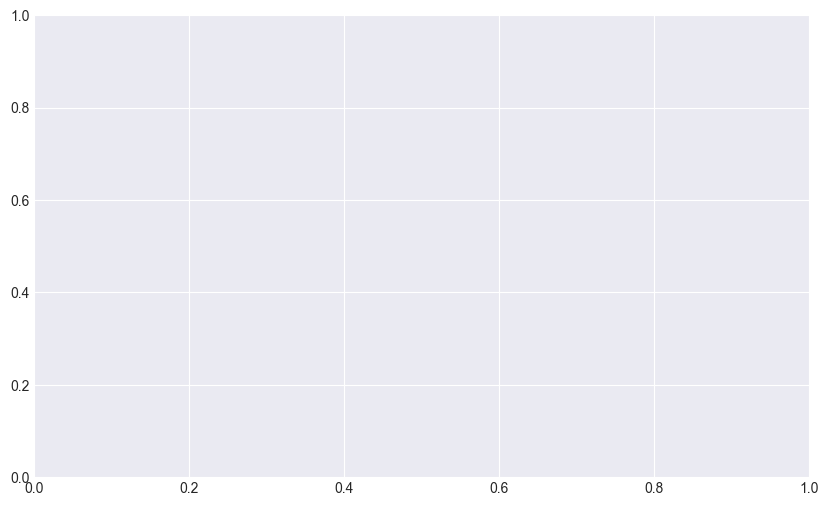

In [4]:
if 'anomaly_score' in df.columns:
    plt.figure(figsize=(10, 6))
    sns.histplot(data=df, x='anomaly_score', hue='anomaly_category', bins=15, kde=True, palette='bright', multiple='stack')
    plt.title('Absolute Output Variance of Anomaly Rule Engine (0-15 Scale)', fontsize=14)
    plt.xlabel('Aggregated Behavioral Anomaly Score')
    plt.ylabel('Frequency Constraint')
    plt.axvline(x=5, color='green', linestyle=':', label='Suspicious Boundary')
    plt.axvline(x=9, color='red', linestyle=':', label='Strong Anomaly Boundary')
    plt.legend()
    plt.show()